More Python Examples reading CEFI
===

## Packages used
To use python to access the ERDDAP server directly from your python script or jupyter-notebook, you will need
- Xarray
- ArrayLake
- netcdf4
- matplotlib

Let's switch our focus to using the Northwest Atlantic dataset on the original model grid. All of the models being distributed via CEFI are the original 
curvi-linear model grid and it is often a good idea to use the data on the original grid because the regridding algorithm can introduce some inaccurracies.

In [6]:
from arraylake import Client
import xarray as xr

client = Client()
client.login()
repo = client.get_repo("noaa-cefi/cefi-nwa-hindcast-monthly")
session = repo.readonly_session("main")
ds = xr.open_zarr(session.store, zarr_format=3, group="raw/main")
ds

Successfully refreshed tokens! Token stored at /home/users/rhs/.arraylake/token.json

╭───────────────────────────────────────────────── User Details ──────────────────────────────────────────────────╮
│ Name: None None                                                                                                 │
│ Email: roland.schweitzer@noaa.gov                                                                               │
│ Id: 9a16376f-37b7-4c34-83b0-63d0d1dd4b51                                                                        │
╰─────────────────────────────────────────────────────────────────────────────────────────────────────────────────╯

<xarray.Dataset> Size: 4TB
Dimensions:                      (time: 372, yh: 845, xh: 775, z_l: 52,
                                  yq: 846, xq: 776, zi: 76, nv: 2)
Coordinates:
  * time                         (time) datetime64[ns] 3kB 1993-01-16T12:00:0...
  * yh                           (yh) float64 7kB 5.273 5.352 ... 51.91 51.93
  * xh                           (xh) float64 6kB -98.0 -97.92 ... -36.16 -36.08
    geolat                       (yh, xh) float32 3MB dask.array<chunksize=(212, 388), meta=np.ndarray>
    geolon                       (yh, xh) float32 3MB dask.array<chunksize=(212, 388), meta=np.ndarray>
  * z_l                          (z_l) float64 416B 2.5 7.5 ... 6.25e+03
  * yq                           (yq) float64 7kB 5.233 5.312 ... 51.92 51.94
  * xq                           (xq) float64 6kB -98.04 -97.96 ... -36.04
  * zi                           (zi) float64 608B 0.0 2.0 ... 6.25e+03 6.5e+03
  * nv                           (nv) float64 16B 1.0 2.0
Data variables: (12/435)
    Heat_PmE                     (time, yh, xh) float32 974MB dask.array<chunksize=(100, 200, 200), meta=np.ndarray>
    MLD_003_max                  (time, yh, xh) float32 974MB dask.array<chunksize=(100, 200, 200), meta=np.ndarray>
    MLD_EN1                      (time, yh, xh) float32 974MB dask.array<chunksize=(100, 200, 200), meta=np.ndarray>
    MLD_EN1_max                  (time, yh, xh) float32 974MB dask.array<chunksize=(100, 200, 200), meta=np.ndarray>
    MLD_003_min                  (time, yh, xh) float32 974MB dask.array<chunksize=(100, 200, 200), meta=np.ndarray>
    MLD_restrat                  (time, yh, xh) float32 974MB dask.array<chunksize=(100, 200, 200), meta=np.ndarray>
    ...                           ...
    zos                          (time, yh, xh) float32 974MB dask.array<chunksize=(100, 200, 200), meta=np.ndarray>
    zossq                        (time, yh, xh) float32 974MB dask.array<chunksize=(100, 200, 200), meta=np.ndarray>
    wc_vert_int_jo2resp          (time, yh, xh) float32 974MB dask.array<chunksize=(100, 200, 200), meta=np.ndarray>
    wfo                          (time, yh, xh) float32 974MB dask.array<chunksize=(100, 200, 200), meta=np.ndarray>
    zmicroos                     (time, yh, xh) float32 974MB dask.array<chunksize=(100, 200, 200), meta=np.ndarray>
    zoocos                       (time, yh, xh) float32 974MB dask.array<chunksize=(100, 200, 200), meta=np.ndarray>
Attributes: (12/18)
    NumFilesInSet:          1
    grid_type:              regular
    grid_tile:              N/A
    cefi_rel_path:          cefi_portal/northwest_atlantic/full_domain/hindca...
    cefi_archive_version:   /archive/acr/fre/NWA/2025_04/NWA12_COBALT_2025_04...
    cefi_run_xml:           N/A
    ...                     ...
    cefi_date_range:        199301-202312
    cefi_init_date:         N/A
    cefi_ensemble_info:     N/A
    cefi_forcing:           N/A
    cefi_data_doi:          10.5281/zenodo.7893386
    cefi_paper_doi:         10.5194/gmd-16-6943-2023

:::{admonition} Science info
:class: info
The map illustrates a clear distinction between high sea levels, primarily from tropical regions (hot and fresh water), and low sea levels, mainly from the Labrador Sea or other polar areas (cold and salty sea water). The meandering pattern of the sharp sea level gradient, indicating rapid sea level changes over a short distance, highlights the location of the Gulf Stream. This distinctive sea level feature is a result of the existence of western boundary currents, commonly observed on the western edges of major ocean basins, such as the Kuroshio in the Pacific basin.
:::

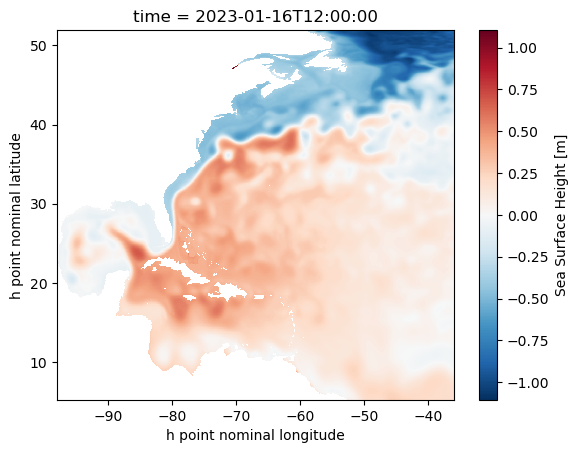

In [7]:
ds['ssh'].sel(time='2023-01-15', method='nearest').plot()

In [16]:
# folium map base map
fm = folium.Map(
    location=[float(da_regrid_data.lat.mean().data), float(da_regrid_data.lon.mean().data)],
    tiles="Cartodb Positron",
    zoom_start=3
)


### Overlay the colored data on the map

In [32]:
folium.raster_layers.ImageOverlay(
    image=colored_data,
    bounds=[[float(da_regrid_data.lat.min().data),
             float(da_regrid_data.lon.min().data)],
            [float(da_regrid_data.lat.max().data),
             float(da_regrid_data.lon.max().data)]],
    mercator_project=True,   # applied data to web mercator projection (essential)
    origin="lower",          # plot data from lower bound (essential)
    opacity=1,
    zindex=1
).add_to(fm)


### Create the colorbar for the interactive map

In [34]:
import numpy as np
tick_inc = np.abs(varmax-varmin)/10.

# start constructing the branca colormap to put on folium map
index_list = range(0,n_increments)    
cmap_list = picked_cm(range(n_increments)).tolist()
cmap_foliump = cm.LinearColormap(
    colors=cmap_list,
    vmin=varmin,
    vmax=varmax,
    caption='fcmap',
    max_labels=n_increments+1,
    tick_labels=list(np.arange(varmin,varmax+tick_inc*0.000001,tick_inc))
).to_step(n_increments)

# Add the colormap to the folium map
cmap_foliump.caption = varname
cmap_foliump.add_to(fm)


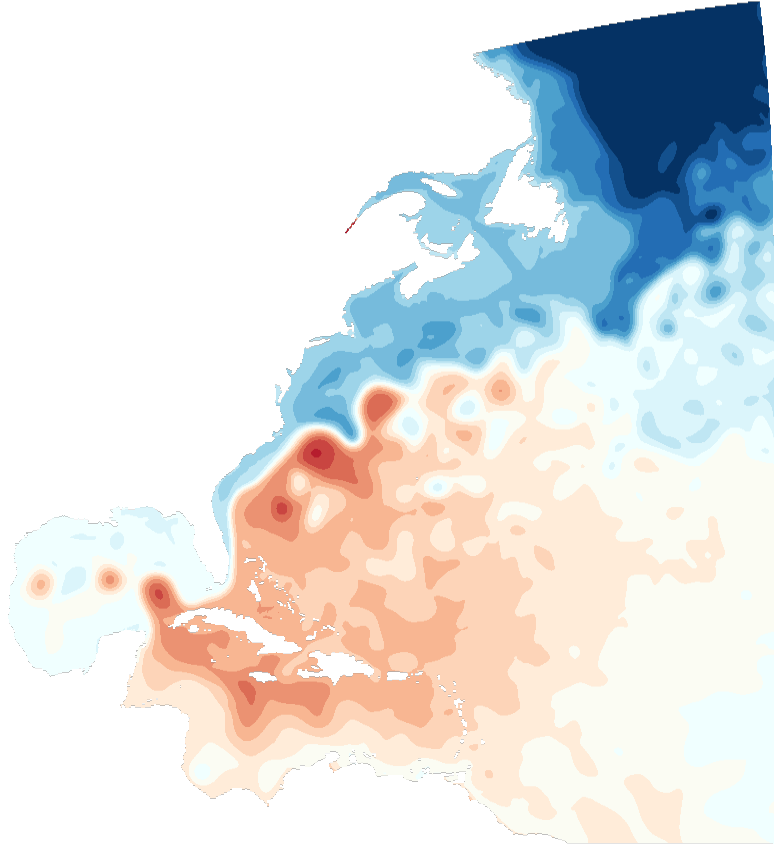

In [35]:
fm

## Access data (raw grid product) 

The raw grid product differs from the regular grid in that it represents the original output of the model. The model grid uses the Arakawa C grid. The [MOM6 documentation](https://mom6.readthedocs.io/en/main/api/generated/pages/Discrete_Grids.html?highlight=arakawa#vertical-grids) provides an excellent visualization of the Arakawa C grid. We can concentrate on the `h` point, which is where scalar values like sea level height are stored. The grid does not have uniform spacing and is, in fact, a curvilinear grid.

:::{admonition} Info
The raw model output is beneficial when calculating the energy budget, which includes factors like heat and momentum. This output preserves each term's original values, avoiding any potential distortions caused by interpolation. By using the raw grid product, we can ensure the energy budget balances within a closed system.
:::


To use the raw grid data, one need to get two files. 
1. the variable file
2. the static file

In [9]:
opendap_url = "http://psl.noaa.gov/thredds/dodsC/Projects/CEFI/regional_mom6/northwest_atlantic/hist_run/ocean_monthly.199301-201912.ssh.nc"
ds_ssh = xr.open_dataset(opendap_url)

opendap_static_url = "http://psl.noaa.gov/thredds/dodsC/Projects/CEFI/regional_mom6/northwest_atlantic/hist_run/ocean_static.nc"
ds_static = xr.open_dataset(opendap_static_url)

In [6]:
ds_ssh

<xarray.Dataset> Size: 849MB
Dimensions:     (time: 324, nv: 2, xh: 775, yh: 845)
Coordinates:
  * nv          (nv) float64 16B 1.0 2.0
  * time        (time) datetime64[ns] 3kB 1993-01-16T12:00:00 ... 2019-12-16T...
  * xh          (xh) float64 6kB -98.0 -97.92 -97.84 ... -36.24 -36.16 -36.08
  * yh          (yh) float64 7kB 5.273 5.352 5.432 5.511 ... 51.9 51.91 51.93
Data variables:
    average_DT  (time) timedelta64[ns] 3kB ...
    average_T1  (time) datetime64[ns] 3kB ...
    average_T2  (time) datetime64[ns] 3kB ...
    ssh         (time, yh, xh) float32 849MB ...
    time_bnds   (time, nv) datetime64[ns] 5kB ...
Attributes:
    NumFilesInSet:                   1
    title:                           NWA12_COBALT_2023_04_kpo4-coastatten-phy...
    associated_files:                areacello: 19930101.ocean_static.nc
    grid_type:                       regular
    grid_tile:                       N/A
    external_variables:              areacello
    history:                         Fri May 12 10:49:27 2023: ncks -4 -L 3 o...
    NCO:                             netCDF Operators version 5.0.1 (Homepage...
    _NCProperties:                   version=2,netcdf=4.9.0,hdf5=1.12.2
    DODS_EXTRA.Unlimited_Dimension:  time

In [7]:
ds_static

<xarray.Dataset> Size: 66MB
Dimensions:       (time: 1, xh: 775, xq: 776, yh: 845, yq: 846)
Coordinates:
  * time          (time) datetime64[ns] 8B 1980-01-01
  * xh            (xh) float64 6kB -98.0 -97.92 -97.84 ... -36.24 -36.16 -36.08
  * xq            (xq) float64 6kB -98.04 -97.96 -97.88 ... -36.2 -36.12 -36.04
  * yh            (yh) float64 7kB 5.273 5.352 5.432 5.511 ... 51.9 51.91 51.93
  * yq            (yq) float64 7kB 5.233 5.312 5.392 5.472 ... 51.9 51.92 51.94
Data variables: (12/25)
    Coriolis      (yq, xq) float32 3MB ...
    areacello     (yh, xh) float32 3MB ...
    areacello_bu  (yq, xq) float32 3MB ...
    areacello_cu  (yh, xq) float32 3MB ...
    areacello_cv  (yq, xh) float32 3MB ...
    deptho        (yh, xh) float32 3MB ...
    ...            ...
    geolon_v      (yq, xh) float32 3MB ...
    sftof         (yh, xh) float32 3MB ...
    wet           (yh, xh) float32 3MB ...
    wet_c         (yq, xq) float32 3MB ...
    wet_u         (yh, xq) float32 3MB ...
    wet_v         (yq, xh) float32 3MB ...
Attributes:
    _NCProperties:                   version=2,netcdf=4.9.0,hdf5=1.12.2
    NumFilesInSet:                   1
    title:                           NWA12_MOM6_v1.0
    grid_type:                       regular
    grid_tile:                       N/A
    history:                         Fri May 12 10:50:21 2023: ncks -4 -L 3 o...
    NCO:                             netCDF Operators version 5.0.1 (Homepage...
    DODS_EXTRA.Unlimited_Dimension:  time

:::{admonition} Tip
:class: tip
Again, only the metadata and coordinate information are loaded into local memory, not the actual data. The gridded data values at each grid point are only downloaded from the PSL server when we append `.load()` to the dataset.
:::



:::{admonition} Warning
:class: tip
In the `ds_static` dataset, you can observe the one-dimensional `xh, yh` grid. The numbers on this grid may resemble longitude and latitude values, but they do not represent actual geographical locations. For accurate longitude and latitude data, you should refer to the `geolon, geolat` variables in the list. These variables, which are dimensioned by `xh, yh`, provide the correct geographical coordinates.
:::

Now let's take a look at the grid area distribution which give a great sense of how it is different from regular spacing grid

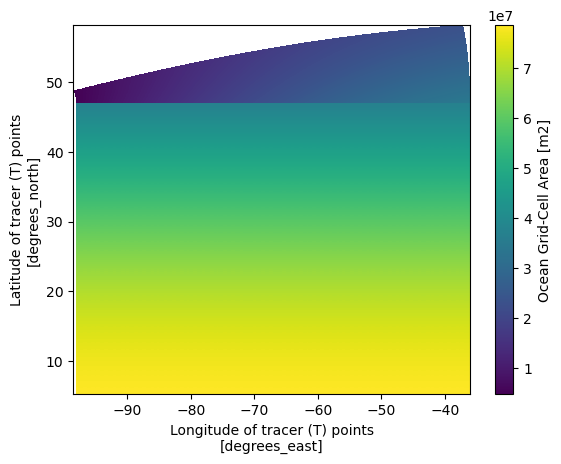

In [13]:
ds_static = ds_static.set_coords(['geolon','geolat'])
ds_static.areacello.plot(x='geolon',y='geolat')

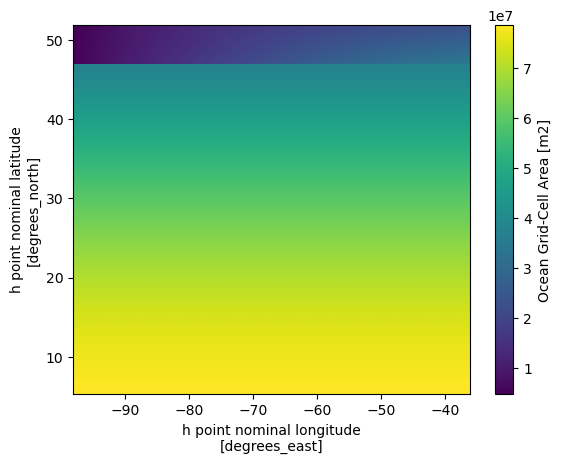

In [14]:
ds_static.areacello.plot(x='xh',y='yh')

We can see that the most significant differences between the two maps are located in the higher latitudes. Since the grid information is important in the raw grid, the easiest way to merge the two dataset so we can have the accurate lon lat that follows the data that we are going to work on.

In [18]:
ds_ssh_subset = ds_ssh.sel(time='2012-12').load()
ds = xr.merge([ds_ssh_subset,ds_static])
ds = ds.isel(time=slice(1,None))  # exclude the 1980 empty field due to merge


In [19]:
ds

<xarray.Dataset> Size: 68MB
Dimensions:       (nv: 2, time: 1, xh: 775, yh: 845, xq: 776, yq: 846)
Coordinates:
  * nv            (nv) float64 16B 1.0 2.0
  * time          (time) datetime64[ns] 8B 2012-12-16T12:00:00
  * xh            (xh) float64 6kB -98.0 -97.92 -97.84 ... -36.24 -36.16 -36.08
  * yh            (yh) float64 7kB 5.273 5.352 5.432 5.511 ... 51.9 51.91 51.93
  * xq            (xq) float64 6kB -98.04 -97.96 -97.88 ... -36.2 -36.12 -36.04
  * yq            (yq) float64 7kB 5.233 5.312 5.392 5.472 ... 51.9 51.92 51.94
    geolat        (yh, xh) float32 3MB ...
    geolon        (yh, xh) float32 3MB ...
Data variables: (12/28)
    average_DT    (time) timedelta64[ns] 8B 31 days
    average_T1    (time) datetime64[ns] 8B 2012-12-01
    average_T2    (time) datetime64[ns] 8B 2013-01-01
    ssh           (time, yh, xh) float32 3MB nan nan nan ... -0.9031 -0.9001
    time_bnds     (time, nv) datetime64[ns] 16B 2012-12-01 2013-01-01
    Coriolis      (yq, xq) float32 3MB ...
    ...            ...
    geolon_v      (yq, xh) float32 3MB ...
    sftof         (yh, xh) float32 3MB ...
    wet           (yh, xh) float32 3MB ...
    wet_c         (yq, xq) float32 3MB ...
    wet_u         (yh, xq) float32 3MB ...
    wet_v         (yq, xh) float32 3MB ...
Attributes:
    NumFilesInSet:                   1
    title:                           NWA12_COBALT_2023_04_kpo4-coastatten-phy...
    associated_files:                areacello: 19930101.ocean_static.nc
    grid_type:                       regular
    grid_tile:                       N/A
    external_variables:              areacello
    history:                         Fri May 12 10:49:27 2023: ncks -4 -L 3 o...
    NCO:                             netCDF Operators version 5.0.1 (Homepage...
    _NCProperties:                   version=2,netcdf=4.9.0,hdf5=1.12.2
    DODS_EXTRA.Unlimited_Dimension:  time

From the xarray dataset object output above, we will notice the `ssh` value in `ds` is now avaible and the coordinate information in teh coordinate is also include into a single Dataset object.

## Quick view of the variable

To check if the data makes sense and fits the chosen time and region, you can use Xarray's `.plot()` method. This way, you see a graph instead of just numbers, making it easier to understand.

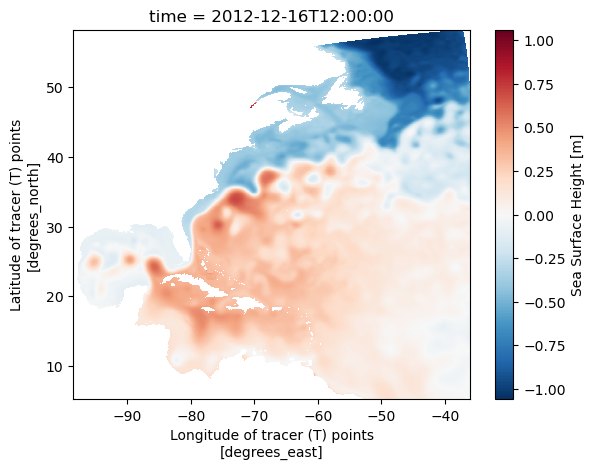

In [20]:
ds.ssh.plot(x='geolon',y='geolat')